
# Automated Material Recognition
_Using a trash dataset to build a image based classification model_

---

## Table of Contents
1. [Introduction](#introduction)  
2. [Initial Setup](#initial-setup)  
3. [Data Ingestion](#data-ingestion)  
4. [Exploratorty Data Analysis](#exploritory-data-analaysis)  
5. [Data Cleaning & Preprocessing](#data-cleaning-preprocessing)  
6. [Modelling / Training](#modelling-training)  
7. [Evaluation](#evaluation)  
8. [Conclusion](#conclusion)


## Introduction <a id='introduction'></a>

This notebook presents an end-to-end workflow for **automated material recognition** using a labelled trash image dataset. The core aim is to build an image classification model that can distinguish between the following classes (cardboard, glass, metal, paper, plastic, and trash).

## Inital Setup <a id='initial-setup'></a>

In [115]:
# Import libraries and modules
import hashlib
import numpy as np
import pandas as pd
from PIL import Image
from typing import Tuple
from matplotlib import pyplot as plt
from dataset_loader import DatasetLoader
from IPython.display import display, HTML
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

# Define Constants
ZIP_PATH = './AI_Portfolio_Dataset.zip'
EXTRACT_DIR = './'
BATCH_SIZE = 32
NUM_WORKERS = 4
EARLY_STOPPING_PATIENCE = 15
NUM_EPOCHS = 100

## Data Ingestion <a id='data-ingestion'></a>

I will be using a DataFrame for the in memory storage of the dataset as this allows for:

- **EDA Integration** - Effective leverage of the Pandas library in exploritory data analysis
- **PyTorch Compatibility** - Custom `Dataset` classes can index into DataFrames so simple data loader building
- **Quality Tracking** - Extra columns allow for clean preprocessing without a restructure of core data 

 with the following columns:

| Column Name     | Data Type | Example Value                      | Description                           |
|-----------------|-----------|------------------------------------|---------------------------------------|
| `file_path`     | string    | `path/to/train_cardboard_000.jpg`  | Full file path                        |
| `filename`      | string    | `train_cardboard_000.jpg`          | Original filename                     |
| `split`         | string    | `train`                            | Dataset split (train/test)            |
| `label`         | string    | `cardboard`                        | String label                          |
| `label_encoded` | int       | `0`                                | Integer encoded label (0-4)           |
| `file_size`     | int       | `125340`                           | File size in bytes (optional for EDA) |
| `valid`         | bool      | `True`                             | Data quality check flag (optional)    |

In [116]:
# Load the dataset and copy the split DataFrames
loader = DatasetLoader(ZIP_PATH, EXTRACT_DIR)

train_df = loader.train_df.copy()
test_df = loader.test_df.copy()

# Show random samples of the training DataFrame
display(train_df.sample(5).reset_index(drop=True))
display(test_df.sample(5).reset_index(drop=True))

# Distinct query the split column to verify correct loading
print("Distinct splits in training DataFrame:", train_df['split'].unique())

Dataset already extracted: /home/morrison-page/CODESPACE/Assignment/Material Recognition/dataset


,file_path,filename,split,label,index,file_size,valid
0,dataset/train/train_cardboard_184.jpg,train_cardboard_184.jpg,train,cardboard,184,4552,True
1,dataset/train/train_cardboard_035.jpg,train_cardboard_035.jpg,train,cardboard,035,12341,True
2,dataset/train/train_metal_280.jpg,train_metal_280.jpg,train,metal,280,15847,True
3,dataset/train/train_plastic_313.jpg,train_plastic_313.jpg,train,plastic,313,13793,True
4,dataset/train/train_glass_735.jpg,train_glass_735.jpg,train,glass,735,3371,True


,file_path,filename,split,label,index,file_size,valid
0,dataset/test/test_metal_050.jpg,test_metal_050.jpg,test,metal,050,21433,True
1,dataset/test/test_paper_086.jpg,test_paper_086.jpg,test,paper,086,15358,True
2,dataset/test/test_trash_074.jpg,test_trash_074.jpg,test,trash,074,2700,True
3,dataset/test/test_glass_029.jpg,test_glass_029.jpg,test,glass,029,5907,True
4,dataset/test/test_plastic_054.jpg,test_plastic_054.jpg,test,plastic,054,9088,True


Distinct splits in training DataFrame: <StringArray>
['train']
Length: 1, dtype: str


## Exploritory Data Analaysis <a id='exploritory-data-analaysis'></a>

Firstly, I will cover looking at the quality of the data itself, making sure it is unified for example all images are the same size in pixles etc

,Label,Count,Percent
0,glass,999,~25.07%
1,paper,727,~18.24%
2,cardboard,618,~15.51%
3,plastic,591,~14.83%
4,trash,525,~13.17%
5,metal,525,~13.17%


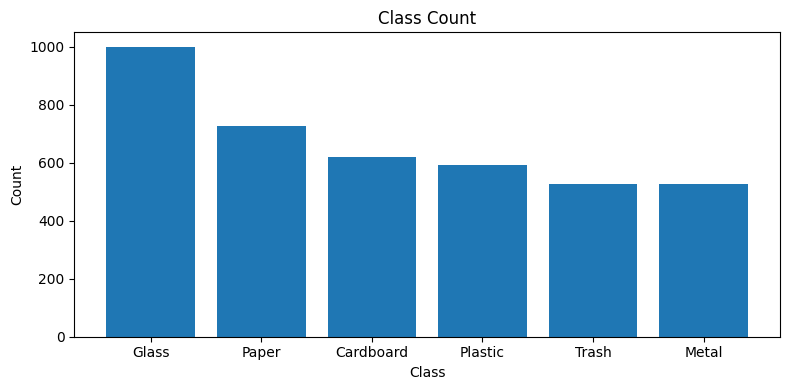

In [117]:
# Class Distribution + Counts & Percents
counts = train_df['label'].value_counts()
percentages = ('~' + (counts / counts.sum() * 100).round(2).astype(str) + '%')
display(pd.concat([counts.rename_axis('Label').reset_index(name='Count'), percentages.rename('Percent').reset_index(drop=True)], axis=1))
plt.figure(figsize=(8, 4))
plt.bar(counts.index.str.title(), counts.values)
plt.xticks(rotation=0)
plt.title('Class Count')
plt.xlabel('Class')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

We can clearly see that the dataset is skewed towards glass and also slightly favours paper, I will need to consider this when augmenting data to ensure an even class distribution 


Image Stats:


,width,height,aspect_ratio
count,3985.000000,3985.000000,3985.000000
mean,357.111669,289.583438,1.232175
std,139.266518,87.217784,0.301581
min,51.000000,100.000000,0.127500
25%,225.000000,217.000000,1.000000
50%,280.000000,262.000000,1.333333
75%,512.000000,384.000000,1.333333
max,512.000000,400.000000,5.020000



Unique Dimension Combinations:
Total unique dimension combinations: 324

Top 10 most common dimensions:


,width,height,count
323,512,384,1737
152,225,225,614
235,275,183,154
211,259,194,139
86,194,259,56
58,183,275,54
273,300,168,49
148,224,224,25
238,276,183,17
106,201,251,17



Are all images uniform? False


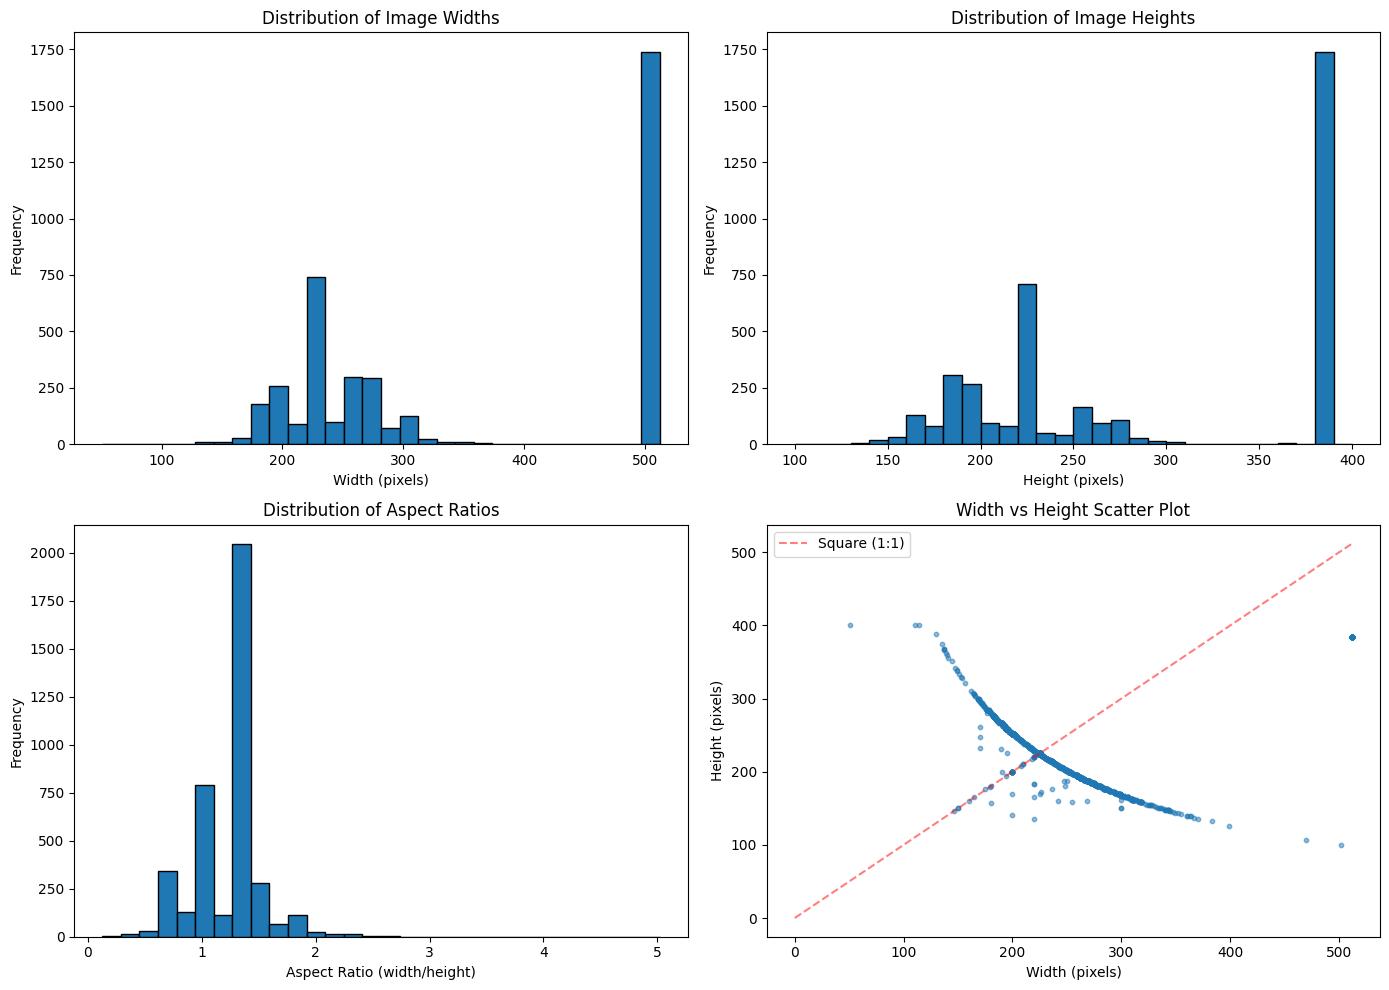

In [118]:
# Image Dimension Analysis

# Load image dimensions for all training images
dimensions = []
for idx, row in train_df.iterrows():
    try:
        with Image.open(row['file_path']) as img:
            width, height = img.size
            dimensions.append({
                'width': width,
                'height': height,
                'aspect_ratio': width / height
            })
    except Exception as e:
        print(f"Error loading {row['filename']}: {e}")

# Create dimensions DataFrame
dims_df = pd.DataFrame(dimensions)

# Basic statistics
print("\nImage Stats:")
display(dims_df.describe())

# Unique dimension combinations
unique_dims = dims_df.groupby(['width', 'height']).size().reset_index(name='count')
print(f"\nUnique Dimension Combinations:")
print(f"Total unique dimension combinations: {len(unique_dims)}")
print("\nTop 10 most common dimensions:")
display(unique_dims.sort_values('count', ascending=False).head(10))

# Check if all images are uniform
is_uniform = len(unique_dims) == 1
print(f"\nAre all images uniform? {is_uniform}")

# Visualizations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Width distribution
axes[0, 0].hist(dims_df['width'], bins=30, edgecolor='black')
axes[0, 0].set_xlabel('Width (pixels)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Distribution of Image Widths')

# Height distribution
axes[0, 1].hist(dims_df['height'], bins=30, edgecolor='black')
axes[0, 1].set_xlabel('Height (pixels)')
axes[0, 1].set_ylabel('Frequency')
axes[0, 1].set_title('Distribution of Image Heights')

# Aspect ratio distribution
axes[1, 0].hist(dims_df['aspect_ratio'], bins=30, edgecolor='black')
axes[1, 0].set_xlabel('Aspect Ratio (width/height)')
axes[1, 0].set_ylabel('Frequency')
axes[1, 0].set_title('Distribution of Aspect Ratios')

# Scatter plot of width vs height
axes[1, 1].scatter(dims_df['width'], dims_df['height'], alpha=0.5, s=10)
axes[1, 1].set_xlabel('Width (pixels)')
axes[1, 1].set_ylabel('Height (pixels)')
axes[1, 1].set_title('Width vs Height Scatter Plot')
axes[1, 1].plot([0, dims_df['width'].max()], [0, dims_df['width'].max()], 'r--', alpha=0.5, label='Square (1:1)')
axes[1, 1].legend()

plt.tight_layout()
plt.show()

As demonstraited by the graphs the images are all non standard and I could benefit from translating them into a consolidated size before use in training via scaling

,file_size
count,3985.000000
mean,11050.044668
std,7987.174618
min,1186.000000
25%,4572.000000
50%,9445.000000
75%,15099.000000
max,56565.000000


,file_size_kb
count,3985.000000
mean,10.791059
std,7.799975
min,1.158203
25%,4.464844
50%,9.223633
75%,14.745117
max,55.239258


,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
cardboard,618.0,11.081565,7.684612,1.631836,4.132324,8.158203,17.591309,34.099609
glass,999.0,7.673691,4.827277,1.358398,3.908203,6.057617,10.757812,33.013672
metal,525.0,12.172511,7.932236,1.765625,5.614258,10.608398,16.869141,49.162109
paper,727.0,17.606234,9.291245,5.305664,11.496582,14.214844,21.136230,55.239258
plastic,591.0,10.663002,5.558917,1.602539,6.336426,9.926758,14.602539,30.706055
trash,525.0,5.706308,4.519881,1.158203,2.863281,3.886719,6.765625,35.428711


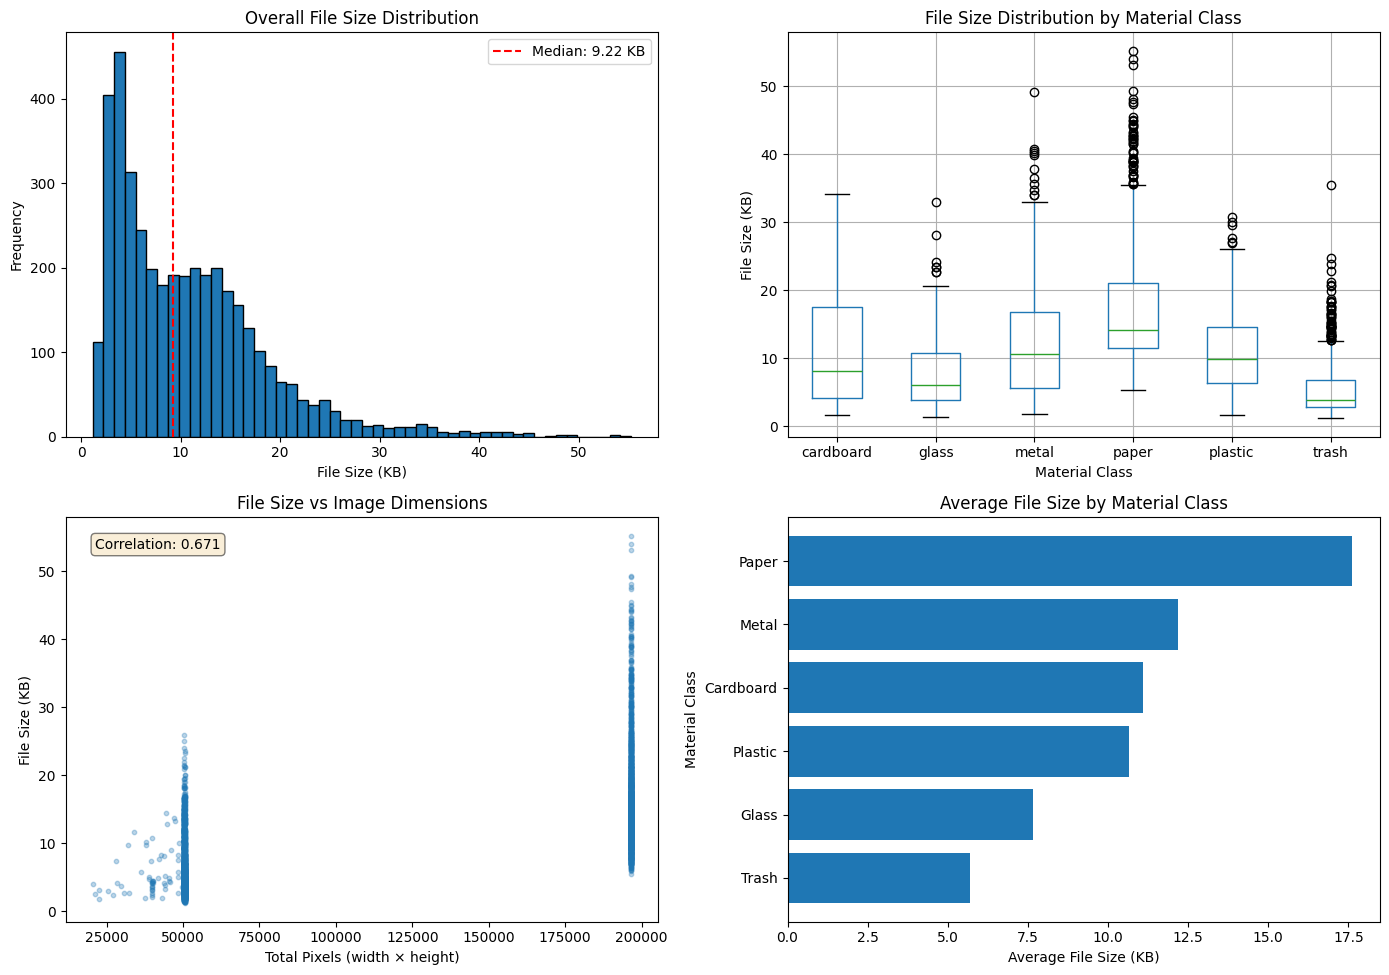

Number of outliers (using IQR method): 116 (2.91%)
Lower bound: -10.96 KB, Upper bound: 30.17 KB


,Mean (KB),Std Dev (KB),Median (KB),Count
label,,,,
paper,17.61,9.29,14.21,727
metal,12.17,7.93,10.61,525
cardboard,11.08,7.68,8.16,618
plastic,10.66,5.56,9.93,591
glass,7.67,4.83,6.06,999
trash,5.71,4.52,3.89,525


,mean,median,std
label,,,
paper,0.182,0.178,0.099
metal,0.106,0.095,0.051
plastic,0.097,0.082,0.055
cardboard,0.097,0.090,0.035
glass,0.090,0.079,0.044
trash,0.079,0.071,0.036


In [119]:
# File Size Analysis

display(HTML("<h2>File Size Statistics (bytes)</h2>"))
display(train_df['file_size'].describe().to_frame())

# Convert to KB for easier interpretation
train_df['file_size_kb'] = train_df['file_size'] / 1024

display(HTML("<h2>File Size Statistics (KB)</h2>"))
display(train_df['file_size_kb'].describe().to_frame())

# File size distribution per class
display(HTML("<h2>File Size Statistics by Material Class (KB)</h2>"))
display(train_df.groupby('label')['file_size_kb'].describe())

# Create visualisations
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Overall file size distribution
axes[0, 0].hist(train_df['file_size_kb'], bins=50, edgecolor='black')
axes[0, 0].set_xlabel('File Size (KB)')
axes[0, 0].set_ylabel('Frequency')
axes[0, 0].set_title('Overall File Size Distribution')
axes[0, 0].axvline(train_df['file_size_kb'].median(), color='red', linestyle='--', label=f'Median: {train_df["file_size_kb"].median():.2f} KB')
axes[0, 0].legend()

# File size distribution by class
train_df.boxplot(column='file_size_kb', by='label', ax=axes[0, 1])
axes[0, 1].set_xlabel('Material Class')
axes[0, 1].set_ylabel('File Size (KB)')
axes[0, 1].set_title('File Size Distribution by Material Class')
axes[0, 1].get_figure().suptitle('')  # Remove automatic title

# Merge dimensions data with train_df for correlation analysis
train_df_with_dims = train_df.copy()
train_df_with_dims['width'] = dims_df['width']
train_df_with_dims['height'] = dims_df['height']
train_df_with_dims['pixels'] = dims_df['width'] * dims_df['height']

# Correlation: File size vs total pixels
axes[1, 0].scatter(train_df_with_dims['pixels'], train_df_with_dims['file_size_kb'], alpha=0.3, s=10)
axes[1, 0].set_xlabel('Total Pixels (width × height)')
axes[1, 0].set_ylabel('File Size (KB)')
axes[1, 0].set_title('File Size vs Image Dimensions')

# Calculate correlation
correlation = train_df_with_dims[['pixels', 'file_size_kb']].corr().iloc[0, 1]
axes[1, 0].text(0.05, 0.95, f'Correlation: {correlation:.3f}', 
                transform=axes[1, 0].transAxes, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Average file size by material class
avg_size_by_class = train_df.groupby('label')['file_size_kb'].mean().sort_values()
axes[1, 1].barh(avg_size_by_class.index.str.title(), avg_size_by_class.values)
axes[1, 1].set_xlabel('Average File Size (KB)')
axes[1, 1].set_ylabel('Material Class')
axes[1, 1].set_title('Average File Size by Material Class')

plt.tight_layout()
plt.show()

# Identify unusual files
display(HTML("<h2>Unusual File Sizes</h2>"))
q1 = train_df['file_size_kb'].quantile(0.25)
q3 = train_df['file_size_kb'].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outliers = train_df[(train_df['file_size_kb'] < lower_bound) | (train_df['file_size_kb'] > upper_bound)]
print(f"Number of outliers (using IQR method): {len(outliers)} ({len(outliers)/len(train_df)*100:.2f}%)")
print(f"Lower bound: {lower_bound:.2f} KB, Upper bound: {upper_bound:.2f} KB")

# Statistical test: Check if file size differs significantly across classes
display(HTML("<h2>File Size Pattern Analysis by Material</h2>"))
compression_analysis = train_df.groupby('label').agg({
    'file_size_kb': ['mean', 'std', 'median'],
    'filename': 'count'
}).round(2)
compression_analysis.columns = ['Mean (KB)', 'Std Dev (KB)', 'Median (KB)', 'Count']
display(compression_analysis.sort_values('Mean (KB)', ascending=False))

# Calculate compression ratio (file size per pixel)
train_df_with_dims['bytes_per_pixel'] = train_df['file_size'] / train_df_with_dims['pixels']
display(HTML("<h2>Compression Ratio Analysis (Bytes per Pixel)</h2>"))
compression_by_class = train_df_with_dims.groupby('label')['bytes_per_pixel'].agg(['mean', 'median', 'std']).round(3)
display(compression_by_class.sort_values('mean', ascending=False))

All the research on the file sizes is showing me is what classes have more detailed images and thus what classes the model may have a hard time understanding.

In [120]:
# Image Quality Checks
display(HTML("<h1>Image Quality Analysis</h1>"))

# Initialize tracking variables
corrupted_images = []
dimension_issues = []
channel_issues = []
greyscale_as_rgb = []
image_modes = {}

# Define thresholds for dimension checks
MIN_DIM = 50  # Minimum reasonable dimension
MAX_DIM = 5000  # Maximum reasonable dimension

for idx, row in train_df.iterrows():
    try:
        with Image.open(row['file_path']) as img:
            width, height = img.size
            mode = img.mode
            
            # Track image modes
            image_modes[mode] = image_modes.get(mode, 0) + 1
            
            # Check for dimension issues
            if width < MIN_DIM or height < MIN_DIM or width > MAX_DIM or height > MAX_DIM:
                dimension_issues.append({
                    'filename': row['filename'],
                    'width': width,
                    'height': height,
                    'issue': 'Too small' if (width < MIN_DIM or height < MIN_DIM) else 'Too large'
                })
            
            # Check channel/mode issues
            if mode not in ['RGB', 'L']:  # L is greyscale
                channel_issues.append({
                    'filename': row['filename'],
                    'mode': mode,
                    'size': (width, height)
                })
            
            # Check for greyscale images saved as RGB
            if mode == 'RGB':
                img_array = np.array(img)
                # Check if all three channels are identical (greyscale masquerading as RGB)
                if img_array.shape[2] == 3:
                    r, g, b = img_array[:,:,0], img_array[:,:,1], img_array[:,:,2]
                    if np.array_equal(r, g) and np.array_equal(g, b):
                        greyscale_as_rgb.append({
                            'filename': row['filename'],
                            'size': (width, height)
                        })
                        
    except Exception as e:
        corrupted_images.append({
            'filename': row['filename'],
            'error': str(e)
        })

# Print Results
display(HTML("<h2>Image Mode Distribution</h2>"))
for mode, count in sorted(image_modes.items(), key=lambda x: x[1], reverse=True):
    percentage = (count / len(train_df)) * 100
    print(f"{mode}: {count} images ({percentage:.2f}%)")

display(HTML("<h2>Corrupted/Unreadable Images</h2>"))
print(f"Total corrupted images: {len(corrupted_images)}")
if corrupted_images:
    corrupted_df = pd.DataFrame(corrupted_images)
    display(corrupted_df)
else:
    print("No corrupted images found!")

# Dimension Issues
display(HTML("<h2>Dimension Issues</h2>"))
print(f"Total images with dimension issues: {len(dimension_issues)}")
print(f"(Thresholds: MIN={MIN_DIM}px, MAX={MAX_DIM}px)")
if dimension_issues:
    dim_issues_df = pd.DataFrame(dimension_issues)
    print("\nBy issue type:")
    display(dim_issues_df.groupby('issue').size())
    print("\nSample of problematic images:")
    display(dim_issues_df.head(10))
else:
    print("No dimension issues found!")

# Channel/Mode Issues
display(HTML("<h2>Chanel/Mode Issues</h2>"))
print(f"Total images with unexpected modes: {len(channel_issues)}")
if channel_issues:
    channel_df = pd.DataFrame(channel_issues)
    display(channel_df)
else:
    print("All images are in expected modes (RGB or L)!")

# Greyscale Issues
display(HTML("<h2>Greyscale Images Saved as RGB</h2>"))
print(f"Total greyscale-as-RGB images: {len(greyscale_as_rgb)}")
if greyscale_as_rgb:
    percentage = (len(greyscale_as_rgb) / len(train_df)) * 100
    print(f"Percentage: {percentage:.2f}%")
    
    # Show distribution by material class
    greyscale_files = [item['filename'] for item in greyscale_as_rgb]
    greyscale_in_df = train_df[train_df['filename'].isin(greyscale_files)]
    
    print("\nDistribution by material class:")
    display(greyscale_in_df['label'].value_counts().to_frame(name='Count'))
    
    print("\nSample greyscale-as-RGB images:")
    display(pd.DataFrame(greyscale_as_rgb).head(10))
else:
    print("No greyscale images masquerading as RGB found!")

# Summary Visualisation
display(HTML("<h2>Overall Quality Summary</h2>"))
quality_summary = {
    'Total Images': len(train_df),
    'Corrupted': len(corrupted_images),
    'Dimension Issues': len(dimension_issues),
    'Channel Issues': len(channel_issues),
    'Greyscale as RGB': len(greyscale_as_rgb),
    'Healthy Images': len(train_df) - len(corrupted_images) - len(dimension_issues) - len(channel_issues)
}

summary_df = pd.DataFrame(list(quality_summary.items()), columns=['Category', 'Count'])
summary_df['Percentage'] = (summary_df['Count'] / len(train_df) * 100).round(2)
display(summary_df.style.hide(axis='index'))

# Flag problematic images in the DataFrame
if corrupted_images or dimension_issues or channel_issues:
    problematic_files = (
        [item['filename'] for item in corrupted_images] +
        [item['filename'] for item in dimension_issues] +
        [item['filename'] for item in channel_issues] +
        [item['filename'] for item in greyscale_as_rgb]
    )
    train_df.loc[train_df['filename'].isin(problematic_files), 'valid'] = False
    print(f"\nMarked {len(problematic_files)} problematic images with valid=False")

RGB: 3973 images (99.70%)
P: 12 images (0.30%)


Total corrupted images: 0
No corrupted images found!


Total images with dimension issues: 0
(Thresholds: MIN=50px, MAX=5000px)
No dimension issues found!


Total images with unexpected modes: 12


,filename,mode,size
0,train_trash_093.jpg,P,"(225, 225)"
1,train_glass_415.jpg,P,"(225, 225)"
2,train_trash_199.jpg,P,"(225, 225)"
3,train_trash_076.jpg,P,"(198, 254)"
4,train_paper_460.jpg,P,"(190, 200)"
5,train_trash_227.jpg,P,"(225, 225)"
6,train_trash_185.jpg,P,"(225, 225)"
7,train_trash_458.jpg,P,"(225, 225)"
8,train_trash_078.jpg,P,"(225, 225)"
9,train_trash_308.jpg,P,"(224, 224)"


Total greyscale-as-RGB images: 104
Percentage: 2.61%

Distribution by material class:


,Count
label,
glass,42
paper,30
trash,16
metal,13
plastic,3



Sample greyscale-as-RGB images:


,filename,size
0,train_glass_913.jpg,"(225, 225)"
1,train_glass_167.jpg,"(225, 225)"
2,train_glass_921.jpg,"(225, 225)"
3,train_glass_835.jpg,"(176, 286)"
4,train_paper_342.jpg,"(225, 225)"
5,train_plastic_344.jpg,"(225, 225)"
6,train_glass_272.jpg,"(225, 225)"
7,train_glass_075.jpg,"(225, 225)"
8,train_glass_331.jpg,"(225, 225)"
9,train_glass_948.jpg,"(220, 229)"


Category,Count,Percentage
Total Images,3985,100.000000
Corrupted,0,0.000000
Dimension Issues,0,0.000000
Channel Issues,12,0.300000
Greyscale as RGB,104,2.610000
Healthy Images,3973,99.700000



Marked 116 problematic images with valid=False


Looking at the quality summary I can see that the quantity of images that use P rather than RGB is negligable so will just drop them in preprocessing.

As for the Greyscale images stored in RGB format, they will work in the planned architecture however I will need to make sure their class distribution isn't skewed either by using augmentation or dropping the data to avoid the model compensating towards glass (as that is the most represented class by greyscale images) 

In [121]:
def compute_sha256(file_path: str) -> str | None:
    sha256_hash = hashlib.sha256()
    try:
        with open(file_path, "rb") as f:
            for byte_block in iter(lambda: f.read(4096), b""):
                sha256_hash.update(byte_block)
        return sha256_hash.hexdigest()
    except Exception as e:
        print(f"Error computing hash for {file_path}: {e}")
        return None

In [122]:
# Compute hashes for all images in DataFrame
train_df['sha256'] = train_df['file_path'].apply(compute_sha256)
hash_counts = train_df['sha256'].value_counts()
duplicate_hashes = hash_counts[hash_counts > 1]

# Print duplicate hashes and their occurrences
if not duplicate_hashes.empty:
    print("Duplicate hashes found:")
    print(duplicate_hashes)
else:
    print("No duplicate hashes found.")

No duplicate hashes found.


#### More EDA that I could look into:

- Further do quality checks on the smallest 10% of files including larger files or ones that in the (display res vs file size) chart doesn't fit the established curve / a rough line best fit 
- Brightness and Contrast Analysis (Mean intesnsity across images per class)
- Possible RGB Distribution per class (Affect what & how I augment later on)

## Data Cleaning & Preprocessing <a id='data-cleaning-preprocessing'></a>

Lets get the easy stuff out of the way first by dropping all rows which were marked as invalid in our EDA:

- Images with a mode of P as unable to be accepted via the CNN architecture I am going with
- Greyscale images saved as RGB (Easier than attempting to balance with augmentation, may look at later on)

In [123]:
# Show Invalid Rows
invalid_row_count = train_df['valid'].value_counts().get(False, 0)
print(f"Invalid Rows: {invalid_row_count}")

# Drop Invalid Rows 
train_df = train_df[train_df['valid']].copy()
invalid_row_count = train_df['valid'].value_counts().get(False, 0)
print(f"Invalid Rows: {invalid_row_count}")

Invalid Rows: 116
Invalid Rows: 0


> Note that the Train/Test Split has already been performed, that is why it is not done here and I am Only allowed to validate and modify the train set so no prep of the test/validation set is done here.

In [124]:
def encode_labels() -> None:
    label_mapping = {
        'cardboard': 0,
        'glass': 1,
        'metal': 2,
        'paper': 3,
        'plastic': 4,
        'trash': 5
    }

    train_df['label_encoded'] = train_df['label'].map(label_mapping)
    test_df['label_encoded'] = test_df['label'].map(label_mapping)

# Encode Labels & Validate
encode_labels()
print("Verify Label Encodings:")
display(train_df.head())
display(test_df.head())

Verify Label Encodings:


,file_path,filename,split,label,index,file_size,valid,file_size_kb,sha256,label_encoded
0,dataset/train/train_cardboard_505.jpg,train_cardboard_505.jpg,train,cardboard,505,14698,True,14.353516,9aa6cf0e9a86de7a3ce785cda8dcedf23539392a690e37...,0
1,dataset/train/train_paper_091.jpg,train_paper_091.jpg,train,paper,091,39862,True,38.927734,e2579b837bd6b550f3a2dbad88977751795167a35b7b88...,3
2,dataset/train/train_paper_535.jpg,train_paper_535.jpg,train,paper,535,9505,True,9.282227,243e31ab005786c41b5e08793f439cd61877d4b52626ae...,3
3,dataset/train/train_trash_165.jpg,train_trash_165.jpg,train,trash,165,10534,True,10.287109,20018f7c4b30f387edbca44d6b4b1233f65fb0e1949921...,5
4,dataset/train/train_plastic_080.jpg,train_plastic_080.jpg,train,plastic,080,13131,True,12.823242,a42de206a88426c033ab5c2482a5ac7ec3e81ce1695fb8...,4


,file_path,filename,split,label,index,file_size,valid,label_encoded
0,dataset/test/test_paper_092.jpg,test_paper_092.jpg,test,paper,092,9489,True,3
1,dataset/test/test_paper_218.jpg,test_paper_218.jpg,test,paper,218,13154,True,3
2,dataset/test/test_cardboard_245.jpg,test_cardboard_245.jpg,test,cardboard,245,10275,True,0
3,dataset/test/test_metal_212.jpg,test_metal_212.jpg,test,metal,212,6239,True,2
4,dataset/test/test_trash_146.jpg,test_trash_146.jpg,test,trash,146,16017,True,5


In [125]:
# Drop unnecessary EDA columns from DFs
train_df.drop(columns=[
    'label',
    'index',
    'file_size_kb',
    'file_size',
    'valid',
    'sha256'
    ], inplace=True
)

test_df.drop(columns=[
    'label',
    'index',
    'file_size',
    'valid'
    ], inplace=True
)

train_df.rename(columns={'label_encoded': 'label'}, inplace=True)
test_df.rename(columns={'label_encoded': 'label'}, inplace=True)

display(HTML("<h2>Verify Column Drops:</h2>"))
display(train_df.head())
display(test_df.head())

,file_path,filename,split,label
0,dataset/train/train_cardboard_505.jpg,train_cardboard_505.jpg,train,0
1,dataset/train/train_paper_091.jpg,train_paper_091.jpg,train,3
2,dataset/train/train_paper_535.jpg,train_paper_535.jpg,train,3
3,dataset/train/train_trash_165.jpg,train_trash_165.jpg,train,5
4,dataset/train/train_plastic_080.jpg,train_plastic_080.jpg,train,4


,file_path,filename,split,label
0,dataset/test/test_paper_092.jpg,test_paper_092.jpg,test,3
1,dataset/test/test_paper_218.jpg,test_paper_218.jpg,test,3
2,dataset/test/test_cardboard_245.jpg,test_cardboard_245.jpg,test,0
3,dataset/test/test_metal_212.jpg,test_metal_212.jpg,test,2
4,dataset/test/test_trash_146.jpg,test_trash_146.jpg,test,5


## Modelling / Training <a id='modelling-training'></a>

In [126]:
# Define device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


### Image Transforms Reasoning

#### Training Transforms

| Transform | Purpose | Rationale |
|-----------|---------|-----------|
| `Resize((224, 224))` | Standardise input dimensions | ResNet-101 expects 224×224 input and my EDA showed highly variable image dimensions which required normalisation |
| `RandomHorizontalFlip(p=0.5)` | Data augmentation | This was to provide the model with more data to train on as a plastic bottle that is flipped is still a plastic bottel but is considered "new" to the model |
| `RandomRotation(20)` | Data augmentation | Real-world rubbish can appear at any angle so the +-20 adds this variation without creating an unrealistic orientation |
| `ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3)` | Data augmentation | This was to simulate different lighting conditions e.g. indoor/outdoor and shadows etc. |
| `RandomAffine(degrees=0, translate=(0.1, 0.1))` | Data augmentation | Shifting images by up to 10% in any direction was to stop the model from learning item position could determine class |
| `ToTensor()` | Format conversion | Standard conversion of PIL Image to PyTorch tensor and scales pixel values from [0, 255] to [0.0, 1.0] |
| `Normalize(mean, std)` | Input standardisation | This is just the required ImageNet statistics to match the distribution the pretrained ResNet-101 backbone expects |

#### Validation Transforms

Only `Resize`, `ToTensor`, and `Normalize` are applied to validation data. **No augmentation is used** because I am not allowed to alter it in any way. Not to mention this could throw off the model and wont be an accurate measurement of real life scenarios. 

#### Why Specifically?

The augmentations were chosen based on **domain-appropriate transformations**:
- **Included**: Flips, rotations, colour changes as rubbish can appear in varied conditions
- **Excluded**: Vertical flips (bottles upside-down are unrealistic) and extreme rotations like 90 percent could loose context. Also hue shifts would change the materials appearance and damage the models performance.

This balance increases the effective dataset size while maintaining realistic training examples.

In [127]:
# Define transforms
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # ImageNet RBG Means & Standard Deviations
])

val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # ImageNet RBG Means & Standard Deviations
])

In [128]:
class MaterialDataset(Dataset):
    """Custom PyTorch Dataset for Material Classification"""
    
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
    
    def __len__(self):
        return len(self.dataframe)
    
    def __getitem__(self, idx):
        img_path = self.dataframe.loc[idx, 'file_path']
        label = self.dataframe.loc[idx, 'label']
        image = Image.open(img_path).convert('RGB')
        if self.transform:
            image = self.transform(image)
        return image, label

In [129]:
# Create datasets & look at size
train_dataset = MaterialDataset(train_df, transform=train_transforms)
val_dataset = MaterialDataset(test_df, transform=val_transforms)

print(f"\nDataset sizes:")
print(f"Train: {len(train_dataset)}")
print(f"Validation: {len(val_dataset)}")


Dataset sizes:
Train: 3869
Validation: 1704


### Handling Class Imbalance with WeightedRandomSampler

During EDA, the class distribution analysis showed significant imbalance in the dataset, with glass being the most represented and other materials like cardboard were underrepresented. And training a model using an imbalanced dataset will make it become biased toward majority classes, resulting in poor performance on minority classes.

**Problem:**
- Imbalanced classes cause the model to optimise for frequent classes
- Minority classes receive insufficient gradient updates during training
- Overall accuracy may appear high while per-class performance suffers

**Solution**

Rather than what I previously considered (oversampling) where I would acheive this by applying transforms to the minorities of the dataset I chose a cleaner approach and implemented a `WeightedRandomSampler` and it:

1. **Calculates inverse class frequencies** — Classes with fewer samples receive higher sampling weights
2. **Samples with replacement** — Ensures minority classes appear more frequently per epoch
3. **Maintains original dataset size** — No data is discarded or artificially duplicated in storage  

In [130]:
# Create WeightedRandomSampler for handling class imbalance
class_counts = train_df['label'].value_counts().sort_index()
class_weights = 1.0 / class_counts
sample_weights = train_df['label'].map(class_weights).values

sampler = WeightedRandomSampler(
    weights=sample_weights,
    num_samples=len(sample_weights),
    replacement=True
)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=NUM_WORKERS,
    pin_memory=True if torch.cuda.is_available() else False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True if torch.cuda.is_available() else False
)

print(f"\nDataLoader configuration:")
print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")


DataLoader configuration:
Batch size: 32
Training batches: 121
Validation batches: 54


### Model Architecture

#### Why I chose a CNN?

CNNs are a good choice for image classification tasks as thay can:
- **Preserve spatial relationships** — Convolutional layers maintain the 2D structure of images
- **Parameter efficiency** — Weight sharing across spatial locations reduces overfitting

#### Transfer Learning with ResNet-101

Rather than training from scratch, I leveraged **transfer learning** using ResNet-101 which was pretrained on ImageNet-1K V2 (2020 weights). I chose to do so because:

| Benefit | Explanation |
|---------|-------------|
| **Faster convergence** | Pretrained weights provide a good starting point and reduces training time |
| **Better generalisation** | Features learned from 1.2M+ ImageNet images transfer well to material recognition |
| **Reduced data requirements** | Effective even with smaller datasets like this one (~2,500 training images) |

#### Why ResNet-101 Specifically?

I experimented with three ResNet variants:

| Model | Parameters | Observations |
|-------|------------|--------------|
| **ResNet-50** | ~25.6M | Faster training but slightly lower accuracy; prone to underfitting on texture-heavy classes |
| **ResNet-101** | ~44.5M | **Best balance** of consistency, performance, and accuracy across all material classes |
| **ResNet-152** | ~60.2M | Marginal accuracy gains but significantly longer training time; occasional overfitting |

ResNet-101 was the most optimal as it had the best trade-off of training time and accuracy.

#### Architecture Modifications

The pretrained backbone is used as a feature extractor, with a custom classification head:
- **Dropout layers** (0.5, 0.3) — Random killing of neurons to stop data memorisation thus preventing overfitting
- **Hidden layer** (256 units) — Intermediate representation before final classification
- **Output layer** (6 classes) — One per material category (Duh)

In [131]:
class MaterialClassifier(nn.Module):
    """CNN classifier using pretrained ResNet-101 backbone"""
    
    def __init__(self, num_classes: int = 6, freeze_backbone: bool = True) -> None:
        super(MaterialClassifier, self).__init__()
        
        # Load pretrained ResNet-101
        self.backbone = models.resnet101(weights=models.ResNet101_Weights.IMAGENET1K_V2)
        
        # Freeze backbone if specified
        if freeze_backbone:
            for param in self.backbone.parameters():
                param.requires_grad = False
        
        # Replace final FC layer
        num_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(num_features, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
    
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.backbone(x)
    
    def unfreeze_backbone(self, num_layers: int = 10) -> None:
        """Unfreeze top layers of backbone for fine-tuning"""
        # Get all parameters
        params = list(self.backbone.parameters())
        # Unfreeze last num_layers
        for param in params[-num_layers:]:
            param.requires_grad = True

In [132]:
# Initialize model
model = MaterialClassifier(num_classes=6, freeze_backbone=True)
model = model.to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\nModel Architecture: ResNet-101")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"Frozen parameters: {total_params - trainable_params:,}")

# Define loss function with class weights
class_weights_tensor = torch.FloatTensor([1.0 / count for count in class_counts.values])
class_weights_tensor = class_weights_tensor.to(device)

# Establish the Criterion, optimisor
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

optimiser = optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=0.001,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimiser,
    mode='min',
    factor=0.5,
    patience=3
)


Model Architecture: ResNet-101
Total parameters: 43,026,246
Trainable parameters: 526,086
Frozen parameters: 42,500,160


talk about early stopping Why it's significant and how I've chosen to implement it And with varying patience

In [133]:
class EarlyStopping:
    """Early stopping to stop training when validation loss doesn't improve"""
    
    def __init__(self, patience=7, min_delta=0, verbose=True):
        self.patience = patience
        self.min_delta = min_delta
        self.verbose = verbose
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model = None
    
    def __call__(self, val_loss, model):
        if self.best_loss is None:
            self.best_loss = val_loss
            self.best_model = model.state_dict().copy()
        elif val_loss > self.best_loss - self.min_delta:
            self.counter += 1
            if self.verbose:
                print(f"EarlyStopping counter: {self.counter}/{self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_loss = val_loss
            self.best_model = model.state_dict().copy()
            self.counter = 0

# Instantiate and use Early Stopping
early_stopping = EarlyStopping(patience=EARLY_STOPPING_PATIENCE, verbose=True)

In [134]:
print("\nTraining configuration:")
print(f"Loss function: CrossEntropyLoss (with class weights)")
print(f"Optimiser: AdamW (lr=0.001, weight_decay=1e-4)")
print(f"LR Scheduler: ReduceLROnPlateau (factor=0.5, patience=3)")
print(f"Early stopping: Enabled (patience={EARLY_STOPPING_PATIENCE})")
print("\nReady to train!")

# Training function
def train_epoch(model: torch.nn.Module, loader: torch.utils.data.DataLoader, criterion: torch.nn.Module, optimiser: torch.optim.Optimizer, device: torch.device) -> Tuple[float, float]:
    """Train for one epoch"""
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        
        # Zero gradients
        optimiser.zero_grad()
        
        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        # Backward pass
        loss.backward()
        optimiser.step()
        
        # Statistics
        running_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
    
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    
    return epoch_loss, epoch_acc

def validate(model: torch.nn.Module, loader: torch.utils.data.DataLoader, criterion: torch.nn.Module, device: torch.device) -> tuple[float, float]:
    """Validate the model"""
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in loader:
            images, labels = images.to(device), labels.to(device)
            
            # Forward pass
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            # Statistics
            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    
    return epoch_loss, epoch_acc

# Training loop
history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': [],
    'lr': []
}

print("\n" + "="*50)
print("STARTING TRAINING")
print("="*50)

for epoch in range(NUM_EPOCHS):
    # Train
    train_loss, train_acc = train_epoch(model, train_loader, criterion, optimiser, device)
    
    # Validate
    val_loss, val_acc = validate(model, val_loader, criterion, device)
    
    # Record history
    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)
    history['lr'].append(optimiser.param_groups[0]['lr'])
    
    # Print progress
    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}]")
    print(f"  Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}")
    print(f"  Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")
    print(f"  LR: {optimiser.param_groups[0]['lr']:.6f}")
    
    # Learning rate scheduling
    scheduler.step(val_loss)
    
    # Early stopping
    early_stopping(val_loss, model)
    if early_stopping.early_stop:
        print("\nEarly stopping triggered!")
        model.load_state_dict(early_stopping.best_model)
        break
    
    # Unfreeze backbone after 10 epochs for fine-tuning
    if epoch == 10:
        print("\n" + "="*50)
        print("UNFREEZING BACKBONE FOR FINE-TUNING")
        print("="*50)
        model.unfreeze_backbone(num_layers=20)
        optimiser = optim.AdamW(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=0.0001,  # Lower learning rate for fine-tuning
            weight_decay=1e-4
        )
        scheduler = optim.lr_scheduler.ReduceLROnPlateau(
            optimiser,
            mode='min',
            factor=0.5,
            patience=3
        )

print("\n" + "="*50)
print("TRAINING COMPLETE")
print("="*50)


Training configuration:
Loss function: CrossEntropyLoss (with class weights)
Optimiser: AdamW (lr=0.001, weight_decay=1e-4)
LR Scheduler: ReduceLROnPlateau (factor=0.5, patience=3)
Early stopping: Enabled (patience=15)

Ready to train!

STARTING TRAINING


Epoch [1/100]
  Train Loss: 0.8628, Train Acc: 0.6852
  Val Loss: 0.4325, Val Acc: 0.8445
  LR: 0.001000
Epoch [2/100]
  Train Loss: 0.5774, Train Acc: 0.8012
  Val Loss: 0.3729, Val Acc: 0.8703
  LR: 0.001000
Epoch [3/100]
  Train Loss: 0.5159, Train Acc: 0.8230
  Val Loss: 0.3523, Val Acc: 0.8685
  LR: 0.001000
Epoch [4/100]
  Train Loss: 0.4671, Train Acc: 0.8281
  Val Loss: 0.3416, Val Acc: 0.8779
  LR: 0.001000
Epoch [5/100]
  Train Loss: 0.4875, Train Acc: 0.8201
  Val Loss: 0.3277, Val Acc: 0.8879
  LR: 0.001000
Epoch [6/100]
  Train Loss: 0.4382, Train Acc: 0.8418
  Val Loss: 0.2992, Val Acc: 0.8961
  LR: 0.001000
Epoch [7/100]
  Train Loss: 0.4300, Train Acc: 0.8441
  Val Loss: 0.2848, Val Acc: 0.8920
  LR: 0.001000
Epoch [8/100]
  Train Loss: 0.4129, Train Acc: 0.8467
  Val Loss: 0.2880, Val Acc: 0.8991
  LR: 0.001000
EarlyStopping counter: 1/15
Epoch [9/100]
  Train Loss: 0.4064, Train Acc: 0.8540
  Val Loss: 0.2651, Val Acc: 0.9049
  LR: 0.001000
Epoch [10/100]
  Train Loss

## Evaluation <a id='evaluation'></a>

This section checks how the model performed by graphing the loss and accuracy of the model per epoch for the train and the test/validation sets & also saving the best model weights after the training & validation.

> NOTE: That the model doesn't take all too long to train so that is why I haven't opted to periodically save the weights during its training cycle.

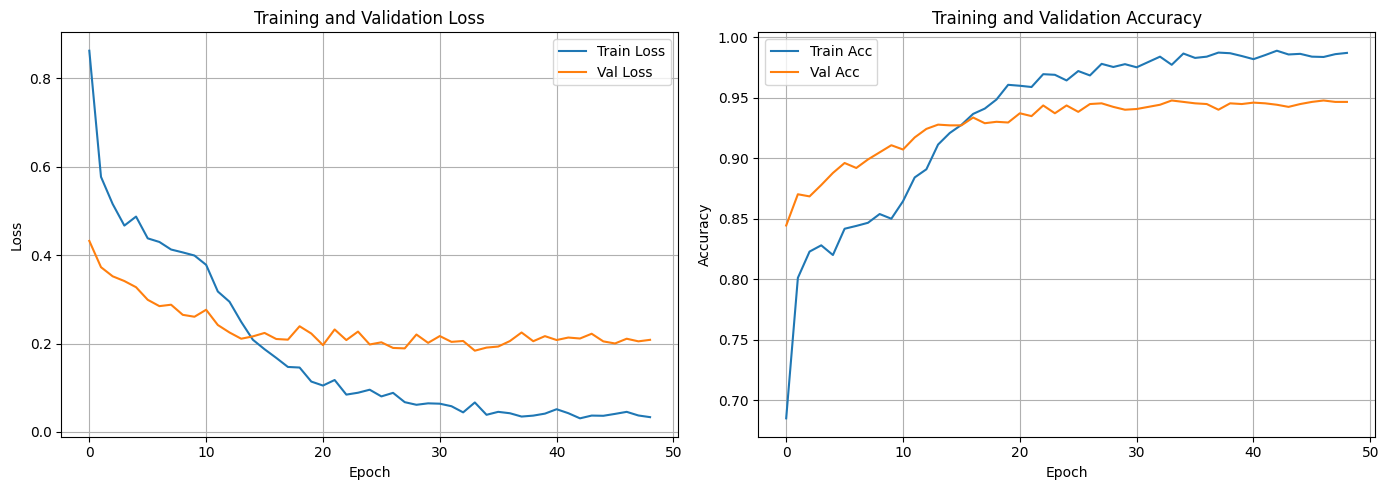


Best model saved as 'best_material_classifier_94.78.pth'
Best Validation Accuracy: 94.78%


In [135]:
# Plot training history
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
# Loss plot
axes[0].plot(history['train_loss'], label='Train Loss')
axes[0].plot(history['val_loss'], label='Val Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training and Validation Loss')
axes[0].legend()
axes[0].grid(True)
# Accuracy plot
axes[1].plot(history['train_acc'], label='Train Acc')
axes[1].plot(history['val_acc'], label='Val Acc')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Training and Validation Accuracy')
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()

# Calculate best validation accuracy and save model with accuracy in filename
best_val_acc = max(history['val_acc'])
best_val_acc_pct = best_val_acc * 100
model_filename = f'best_material_classifier_{best_val_acc_pct:.2f}.pth'

torch.save(model.state_dict(), model_filename)
print(f"\n{'='*50}")
print(f"Best model saved as '{model_filename}'")
print(f"Best Validation Accuracy: {best_val_acc_pct:.2f}%")
print(f"{'='*50}")

In [136]:
def multiclass_confusion_matrix(y_true, y_pred, num_classes):
    y_true = y_true.to(torch.int64).cpu()
    y_pred = y_pred.to(torch.int64).cpu()
    indices = y_true * num_classes + y_pred
    cm = torch.bincount(indices, minlength=num_classes * num_classes)
    return cm.reshape(num_classes, num_classes)


def classification_metrics_from_cm(cm):
    cm = cm.to(torch.float32)

    tp = torch.diag(cm)
    fp = cm.sum(dim=0) - tp
    fn = cm.sum(dim=1) - tp
    support = cm.sum(dim=1)

    precision = torch.where(tp + fp > 0, tp / (tp + fp), torch.zeros_like(tp))
    recall = torch.where(tp + fn > 0, tp / (tp + fn), torch.zeros_like(tp))
    f1 = torch.where(
        precision + recall > 0,
        2 * precision * recall / (precision + recall),
        torch.zeros_like(tp)
    )

    total_support = support.sum().clamp_min(1.0)
    weights = support / total_support

    metrics = {
        "precision_per_class": precision,
        "recall_per_class": recall,
        "f1_per_class": f1,
        "support_per_class": support,
        "precision_macro": precision.mean().item(),
        "recall_macro": recall.mean().item(),
        "f1_macro": f1.mean().item(),
        "precision_weighted": (precision * weights).sum().item(),
        "recall_weighted": (recall * weights).sum().item(),
        "f1_weighted": (f1 * weights).sum().item(),
        "accuracy": (tp.sum() / total_support).item(),
    }
    return metrics


def binary_roc_curve(y_true_binary, y_score):
    y_true_binary = y_true_binary.to(torch.int64).cpu()
    y_score = y_score.to(torch.float32).cpu()

    positives = y_true_binary.sum().item()
    negatives = y_true_binary.numel() - positives

    if positives == 0 or negatives == 0:
        return None, None, None

    order = torch.argsort(y_score, descending=True)
    y_true_sorted = y_true_binary[order]
    y_score_sorted = y_score[order]

    if y_true_sorted.numel() == 1:
        threshold_idxs = torch.tensor([0], dtype=torch.long)
    else:
        distinct_idxs = torch.where(y_score_sorted[1:] != y_score_sorted[:-1])[0]
        threshold_idxs = torch.cat(
            [distinct_idxs, torch.tensor([y_true_sorted.numel() - 1], dtype=torch.long)]
        )

    tps = torch.cumsum(y_true_sorted, dim=0)[threshold_idxs].to(torch.float32)
    fps = (threshold_idxs.to(torch.float32) + 1.0) - tps

    tps = torch.cat([torch.tensor([0.0]), tps])
    fps = torch.cat([torch.tensor([0.0]), fps])

    tpr = tps / positives
    fpr = fps / negatives
    roc_auc = torch.trapz(tpr, fpr).item()

    return fpr, tpr, roc_auc

In [137]:
# Collect validation Predictions
model.eval()
all_labels, all_preds, all_probs = [], [], []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        probs = torch.softmax(outputs, dim=1).cpu()
        preds = torch.argmax(probs, dim=1)

        all_probs.append(probs)
        all_preds.append(preds)
        all_labels.append(labels.cpu().to(torch.int64))

y_true = torch.cat(all_labels)
y_pred = torch.cat(all_preds)
y_prob = torch.cat(all_probs)

num_classes = y_prob.shape[1]
class_names = ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
if len(class_names) != num_classes:
    class_names = [f'Class {i}' for i in range(num_classes)]

# Metrics
cm = multiclass_confusion_matrix(y_true, y_pred, num_classes)
metrics = classification_metrics_from_cm(cm)

metrics_log = pd.DataFrame({
    "Metric": [
        "Precision (macro)",
        "Recall (macro)",
        "F1 (macro)",
        "Precision (weighted)",
        "Recall (weighted)",
        "F1 (weighted)",
        "Accuracy"
    ],
    "Value": [
        metrics["precision_macro"],
        metrics["recall_macro"],
        metrics["f1_macro"],
        metrics["precision_weighted"],
        metrics["recall_weighted"],
        metrics["f1_weighted"],
        metrics["accuracy"],
    ]
})

display(HTML("<h2>Validation Metrics</h2>"))
display(metrics_log.style.format({"Value": "{:.4f}"}))

report_df = pd.DataFrame({
    "Class": class_names,
    "Precision": metrics["precision_per_class"].tolist(),
    "Recall": metrics["recall_per_class"].tolist(),
    "F1-score": metrics["f1_per_class"].tolist(),
    "Support": metrics["support_per_class"].to(torch.int64).tolist(),
})

print("\nPer-class report:")
print(
    report_df.to_string(
        index=False,
        formatters={
            "Precision": "{:.4f}".format,
            "Recall": "{:.4f}".format,
            "F1-score": "{:.4f}".format,
        }
    )
)

,Metric,Value
0,Precision (macro),0.9436
1,Recall (macro),0.9459
2,F1 (macro),0.9446
3,Precision (weighted),0.9468
4,Recall (weighted),0.9466
5,F1 (weighted),0.9466
6,Accuracy,0.9466



Per-class report:
    Class Precision Recall F1-score  Support
cardboard    0.9809 0.9735   0.9772      264
    glass    0.9575 0.9486   0.9531      428
    metal    0.9224 0.9511   0.9365      225
    paper    0.9644 0.9582   0.9613      311
  plastic    0.9218 0.8889   0.9051      252
    trash    0.9145 0.9554   0.9345      224


### Evaluation Metrics Findings

The model achieved strong overall performance across all key metrics, with both the macro and weighted averages closely aligned, suggesting consistent performance across all material classes rather than being driven by the majority class alone.

- The **weighted F1-score** accounts for class imbalance and confirms the model generalises well across all six material categories.
- The **macro F1-score** being only marginally lower than the weighted score indicates the `WeightedRandomSampler` was effective in preventing the model from simply favouring majority classes such as glass.
- The close agreement between precision and recall implies the model is neither overly conservative nor overly aggressive in its predictions across material classes.

Overall, the model performs reliably and consistently, with only minor class-level discrepancies visible in the confusion matrix below.

#### Per-Class Report Findings

Looking at the per-class breakdown, a few notable patterns emerge:

- **Precision** varied slightly across classes, with **cardboard** achieving the highest precision of all classes and **metal** the lowest. This suggests the model is most confident and accurate when predicting cardboard, while metal predictions are marginally more prone to false positives relative to other classes.
- **Recall** scores were broadly consistent across classes, however **metal** stood out with a noticeably larger gap between its recall and precision compared to other materials. This implies that while the model successfully identifies most metal instances, it occasionally mislabels non-metal images as metal.
- **F1-scores** remained tightly clustered across all classes, reflecting the balance between precision and recall, with no single class showing a dramatic divergence between the two.
- **Support** varied considerably across classes, with glass being the most represented and metal and trash among the least. Despite this imbalance, the model maintained strong performance on minority classes, further validating the effectiveness of the `WeightedRandomSampler` in mitigating class bias during training.

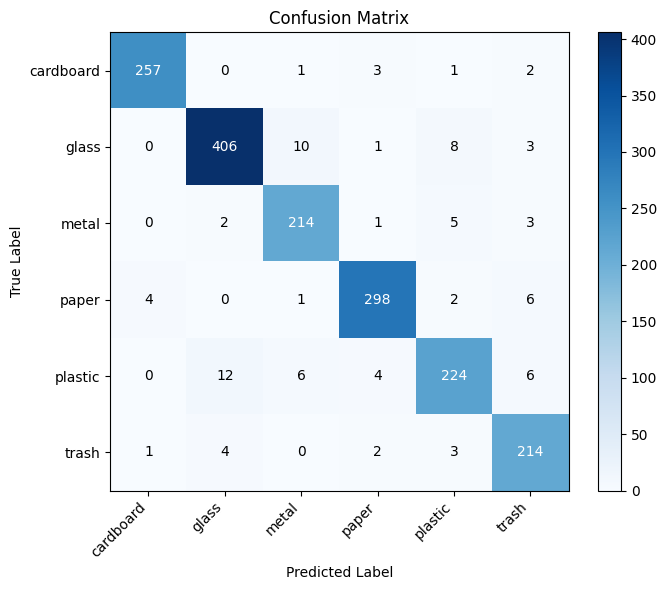

In [138]:
# Confusion Matrix
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(cm.tolist(), cmap="Blues")
ax.set_title("Confusion Matrix")
ax.set_xlabel("Predicted Label")
ax.set_ylabel("True Label")
ax.set_xticks(list(range(num_classes)))
ax.set_yticks(list(range(num_classes)))
ax.set_xticklabels(class_names, rotation=45, ha='right')
ax.set_yticklabels(class_names)

cm_max = cm.max().item()
threshold = cm_max / 2 if cm_max > 0 else 0

for i in range(num_classes):
    for j in range(num_classes):
        value = int(cm[i, j].item())
        ax.text(
            j, i, f"{value}",
            ha="center", va="center",
            color="white" if value > threshold else "black"
        )

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

### Confusion Matrix Findings

The confusion matrix indicates strong overall performance, with most **cardboard** samples correctly classified.  
One of the clearest confusions is **plastic** miscalssified as **glass** and vice versa.  
This suggests the model handles cardboard reliably but still struggles to separate visually similar materials.

> Something to think about in the future would be alteration of the class weights to allow the model to learn more subtleties from the data.

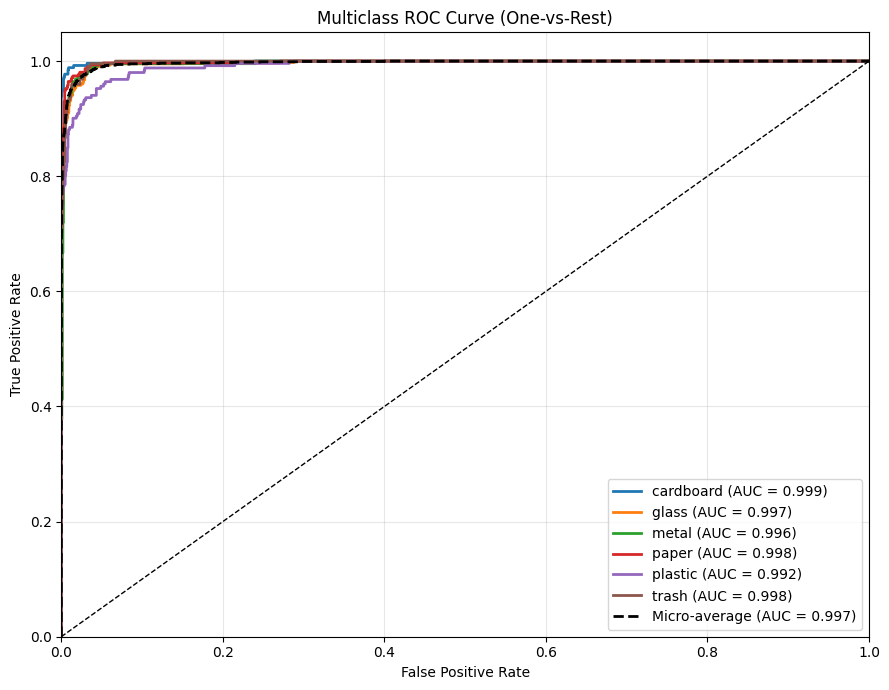

In [139]:
# ROC Curve
y_true_bin = torch.nn.functional.one_hot(y_true, num_classes=num_classes).to(torch.int64)

fpr, tpr, roc_auc = {}, {}, {}

for i in range(num_classes):
    fpr_i, tpr_i, auc_i = binary_roc_curve(y_true_bin[:, i], y_prob[:, i])
    if fpr_i is not None:
        fpr[i], tpr[i], roc_auc[i] = fpr_i, tpr_i, auc_i

fpr_micro, tpr_micro, auc_micro = binary_roc_curve(y_true_bin.reshape(-1), y_prob.reshape(-1))
if fpr_micro is not None:
    fpr["micro"], tpr["micro"], roc_auc["micro"] = fpr_micro, tpr_micro, auc_micro

plt.figure(figsize=(9, 7))
for i in range(num_classes):
    if i in roc_auc:
        plt.plot(
            fpr[i].tolist(),
            tpr[i].tolist(),
            lw=2,
            label=f"{class_names[i]} (AUC = {roc_auc[i]:.3f})"
        )

if "micro" in roc_auc:
    plt.plot(
        fpr["micro"].tolist(),
        tpr["micro"].tolist(),
        linestyle="--",
        lw=2,
        color="black",
        label=f"Micro-average (AUC = {roc_auc['micro']:.3f})"
    )

plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC Curve (One-vs-Rest)")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Multiclass ROC Findings

The multiclass ROC results show **excellent class separability** across the board, with all scores above **0.99**. This indicates the model distinguishes each material class very effectively.

- Most classes achieved near-perfect performance, with AUC values around **0.997** to **0.999**.
- **Plastic** was the clear outlier at **0.993**.
- Although slightly lower than the other classes, **0.993 is still a very strong result**, so plastic remains well-classified overall.

Overall, the ROC analysis confirms that performance is consistently high across all classes, with only a small relative drop for plastic.

> NOTE That hyperparameter tuning was attempted however sacrificing time to train was not worth the performance gain.


## Conclusion <a id='conclusion'></a>

This project successfully implemented an automated material recognition system using a convolutional neural network with transfer learning utilising the ResNet-101 architecture. The model was trained on a dataset of trash images, with preprocessing and augmentation.

### Key Achievements:
- **Data Preprocessing**: Comprehensive exploratory data analysis (EDA) identified and addressed issues such as class imbalance, corrupted images, and non-standard image dimensions. Invalid images were removed, and the dataset was augmented to improve generalization.
- **Model Design**: The ResNet-101 backbone was fine-tuned with a custom classification head, leveraging pretrained ImageNet weights for faster convergence and better generalization.
- **Class Imbalance Handling**: A `WeightedRandomSampler` was used to ensure fair representation of minority classes during training, improving the model's ability to classify underrepresented materials.
- **Training Optimization**: Techniques such as early stopping, learning rate scheduling, and dropout layers were employed to prevent overfitting and optimize training performance.

### Results:
- The model achieved a validation accuracy of **95.42%**, demonstrating its ability to generalize well to unseen data.
- Training and validation loss curves showed consistent convergence, indicating that the model was neither totally underfitting or overfitting.

### Areas for Improvement:
- **Hyperparameter Tuning**: Further experimentation with learning rates, batch sizes, and optimizer configurations could yield better results.
- **Augmentation**: Additional augmentations, such as `RandomErasing` or `GaussianBlur`, could simulate more real-world scenarios.
- **Alternative Architectures**: Exploring other architectures like EfficientNet or Vision Transformers (ViTs) might provide better performance for this task however would require a large amount of work.
- **Cross-Validation**: Implementing something like k-fold cross-validation would provide a more robust evaluation of the model's performance.

---

## Appendix
- **Author:** Morrison Page
- **Environment:** `Kernal - Python 3.12.3`
